Number of teams: 45
Mean intuition-based portfolio value: $101,178.61
Mean indicator-based portfolio value: $103,087.50
Mean difference (indicator minus intuition): $1,908.89
Paired t-test p-value (two-sided): 0.0999


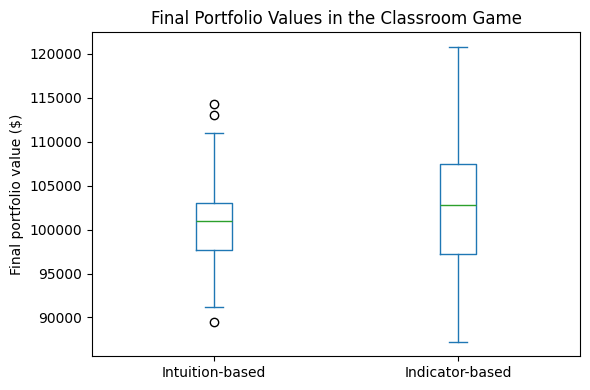

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

# Load the final portfolio values from the classroom game.
game = pd.read_excel("/content/Full_Results copy.xlsx")
game = game[["portfolio1", "portfolio2"]].apply(pd.to_numeric, errors="coerce")

# Keep teams with a recorded value for both portfolios.
game = game.dropna().rename(columns={
    "portfolio1": "Intuition-based",
    "portfolio2": "Indicator-based",
})

# Compare the two portfolios within each team.
intuition = game["Intuition-based"]
indicator = game["Indicator-based"]
difference = indicator - intuition
test = ttest_rel(indicator, intuition)

print(f"Number of teams: {len(game)}")
print(f"Mean intuition-based portfolio value: ${intuition.mean():,.2f}")
print(f"Mean indicator-based portfolio value: ${indicator.mean():,.2f}")
print(f"Mean difference (indicator minus intuition): ${difference.mean():,.2f}")
print(f"Paired t-test p-value (two-sided): {test.pvalue:.4f}")

# Plot the distribution of final portfolio values across teams.
ax = game.plot.box(figsize=(6, 4))
ax.set_title("Final Portfolio Values in the Classroom Game")
ax.set_ylabel("Final portfolio value ($)")
plt.tight_layout()
plt.savefig("classroom_game.png", dpi=200, bbox_inches="tight")
plt.show()

In [3]:
%pip -q install yfinance xgboost openpyxl

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# Use fixed download dates for reproducibility. The end date is exclusive.
START = "2022-01-01"
END = "2026-11-14"
TEST_START = pd.Timestamp("2024-01-01")

tickers = """
AAPL MSFT NVDA GOOG META AMZN AVGO ORCL ADBE CRM
CSCO AMD INTC QCOM TXN IBM NOW INTU AMAT MU
JPM BAC WFC GS MS BLK C SCHW SPGI AXP USB PNC TFC COF
UNH JNJ LLY PFE MRK ABBV TMO DHR ABT BMY AMGN GILD CVS ISRG MDT
TSLA HD MCD NKE SBUX LOW TJX BKNG CMG ORLY
WMT COST PG KO PEP PM MO CL EL
CAT GE HON UPS BA RTX DE LMT MMM ETN
XOM CVX COP SLB EOG
NFLX DIS CMCSA TMUS VZ
AMT PLD NEE DUK SO LIN APD
""".split()

prices = yf.download(
    tickers + ["SPY"],
    start=START,
    end=END,
    auto_adjust=False,
    group_by="ticker",
    progress=False,
)

if prices.empty or "SPY" not in prices.columns.get_level_values(0):
    raise RuntimeError("SPY data could not be downloaded. Please rerun this cell.")

spy_price = prices["SPY"]["Adj Close"].dropna().sort_index()
if spy_price.empty:
    raise RuntimeError("SPY adjusted closing prices are missing. Please rerun this cell.")

spy_return = spy_price.pct_change()
sessions = spy_price.index
session_dates = pd.Series(sessions, index=sessions)

# Generate the signal at the close on day t, enter at the close on day t+1,
# and exit at the close on day t+20.
entry_dates = session_dates.shift(-1)
exit_dates = session_dates.shift(-20)

# The classroom model uses raw price and volume data alongside engineered features.
raw_columns = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
feature_columns = raw_columns + [
    "return", "spy_ret", "mom_1m", "mom_3m", "mom_6m",
    "vol_1m", "ret_5d", "excess_ret",
]

stock_frames = []
missing_tickers = []
available_tickers = prices.columns.get_level_values(0)

for ticker in tickers:
    if ticker not in available_tickers:
        missing_tickers.append(ticker)
        continue

    stock = prices[ticker][raw_columns].reindex(sessions).copy()
    if stock["Adj Close"].isna().all():
        missing_tickers.append(ticker)
        continue

    adjusted = stock["Adj Close"]
    stock["return"] = adjusted.pct_change(fill_method=None)
    stock["spy_ret"] = spy_return

    # Keep the lag formulas and rolling window from the classroom script.
    stock["mom_1m"] = adjusted.shift(21) / adjusted.shift(1) - 1
    stock["mom_3m"] = adjusted.shift(63) / adjusted.shift(1) - 1
    stock["mom_6m"] = adjusted.shift(126) / adjusted.shift(1) - 1
    stock["vol_1m"] = stock["return"].shift(1).rolling(22).std()
    stock["ret_5d"] = adjusted.shift(5) / adjusted.shift(1) - 1
    stock["excess_ret"] = stock["return"] - stock["spy_ret"]

    # Calculate the realized return from the entry close to the exit close.
    stock["target"] = adjusted.shift(-20) / adjusted.shift(-1) - 1
    stock["entry_date"] = entry_dates
    stock["exit_date"] = exit_dates
    stock["date"] = stock.index
    stock["ticker"] = ticker
    stock_frames.append(stock.reset_index(drop=True))

if not stock_frames:
    raise RuntimeError("No usable stock data were downloaded. Please rerun this cell.")

data = pd.concat(stock_frames, ignore_index=True)
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=feature_columns + ["target", "entry_date", "exit_date"])
data = data.sort_values(["date", "ticker"]).reset_index(drop=True)

print(f"Number of stocks in the dataset: {data['ticker'].nunique()}")
print(f"Number of usable observations: {len(data):,}")
print("Tickers with no downloaded data:", ", ".join(missing_tickers) or "None")

Number of stocks in the dataset: 95
Number of usable observations: 102,220
Tickers with no downloaded data: None


In [5]:
# Use only training observations whose returns were fully known
# before the test period began.
train = data.loc[data["exit_date"] < TEST_START].copy()
test = data.loc[data["date"] >= TEST_START].copy()

if train.empty or test.empty:
    raise RuntimeError("The training or test set is empty. Check the download dates and data.")

X_train = train[feature_columns]
y_train = train["target"]
X_test = test[feature_columns]
y_test = test["target"]

# Use the same settings for both models except for maximum tree depth.
common_settings = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "gamma": 0,
    "min_child_weight": 10,
    "objective": "reg:squarederror",
    "random_state": 123,
    "n_jobs": 2,
}

original_model = XGBRegressor(max_depth=5, **common_settings)
shallow_model = XGBRegressor(max_depth=2, **common_settings)

original_model.fit(X_train, y_train)
shallow_model.fit(X_train, y_train)

# Use the average training-period return as the simple prediction benchmark.
test["historical_mean"] = y_train.mean()
test["original_xgb"] = original_model.predict(X_test)
test["shallow_xgb"] = shallow_model.predict(X_test)

model_names = {
    "historical_mean": "Historical mean",
    "original_xgb": "Classroom XGBoost (depth 5)",
    "shallow_xgb": "Shallower XGBoost (depth 2)",
}

# Report prediction errors in percentage points.
rows = []
for column, name in model_names.items():
    rows.append({
        "Model": name,
        "MAE (percentage points)": 100 * mean_absolute_error(y_test, test[column]),
        "RMSE (percentage points)": 100 * np.sqrt(
            mean_squared_error(y_test, test[column])
        ),
    })

metrics = pd.DataFrame(rows).set_index("Model")

print(f"Training observations: {len(train):,}")
print(f"Test observations: {len(test):,}")
print(f"Test signal dates: {test['date'].min():%Y-%m-%d} to {test['date'].max():%Y-%m-%d}")
display(metrics.round(3))

Training observations: 33,725
Test observations: 66,595
Test signal dates: 2024-01-02 to 2026-10-16


,MAE (percentage points),RMSE (percentage points)
Model,,
Historical mean,6.426,8.887
Classroom XGBoost (depth 5),6.849,9.371
Shallower XGBoost (depth 2),6.645,9.126


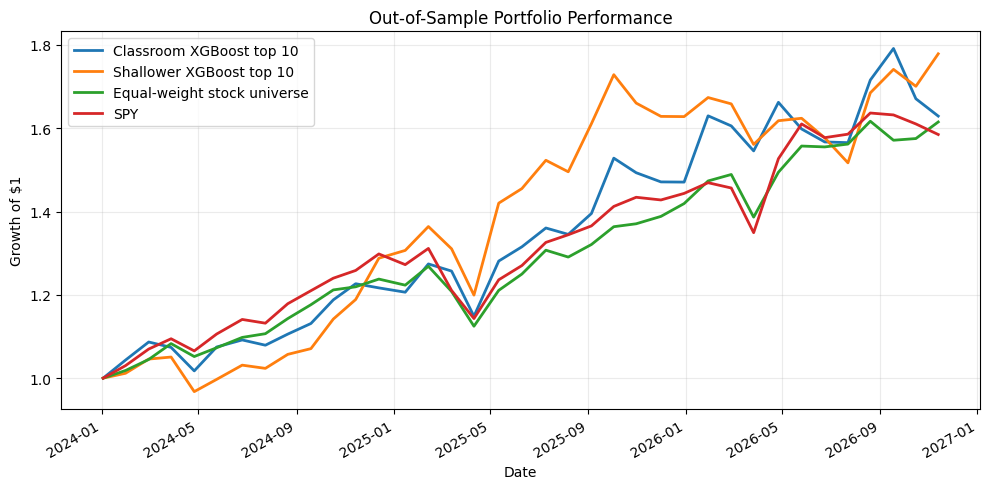

Number of backtest holding periods: 36


,Cumulative return (%)
Classroom XGBoost top 10,62.91
Shallower XGBoost top 10,77.86
Equal-weight stock universe,61.50
SPY,58.48


In [6]:
# Generate signals every 20 trading sessions on the same dates for all strategies.
test_sessions = sessions[sessions >= TEST_START]
signal_dates = test_sessions[::20]
backtest_rows = []

for date in signal_dates:
    candidates = test.loc[test["date"] == date]
    if len(candidates) < 10:
        continue

    entry = candidates["entry_date"].iloc[0]
    exit_ = candidates["exit_date"].iloc[0]

    # Hold the top 10 ranked stocks with equal weights in each model portfolio.
    original_top10 = candidates.nlargest(10, "original_xgb")
    shallow_top10 = candidates.nlargest(10, "shallow_xgb")

    # Compare both portfolios with an equal-weight stock universe and SPY.
    # Use the same entry and exit dates for every strategy.
    backtest_rows.append({
        "entry_date": entry,
        "date": exit_,
        "Classroom XGBoost top 10": original_top10["target"].mean(),
        "Shallower XGBoost top 10": shallow_top10["target"].mean(),
        "Equal-weight stock universe": candidates["target"].mean(),
        "SPY": spy_price.loc[exit_] / spy_price.loc[entry] - 1,
    })

if not backtest_rows:
    raise RuntimeError("No usable backtest periods were found. Check the test dates and stock data.")

backtest = pd.DataFrame(backtest_rows).sort_values("date")
first_entry = backtest["entry_date"].iloc[0]
period_returns = backtest.set_index("date").drop(columns="entry_date")

# Compound returns with zero transaction costs and zero returns between holding periods.
growth = (1 + period_returns).cumprod()

# Start each portfolio at $1 on the first entry date.
starting_value = pd.DataFrame(1.0, index=[first_entry], columns=growth.columns)
growth = pd.concat([starting_value, growth])

ax = growth.plot(figsize=(10, 5), linewidth=2)
ax.set_title("Out-of-Sample Portfolio Performance")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("figure1.png", dpi=200, bbox_inches="tight")
plt.show()

total_return = (growth.iloc[-1] - 1) * 100

print(f"Number of backtest holding periods: {len(period_returns)}")
display(total_return.round(2).rename("Cumulative return (%)").to_frame())

metrics.to_csv("prediction_metrics.csv")
period_returns.to_csv("backtest_returns.csv")